# PPE Detection with YOLO

Fine-tune a YOLO26s model on the Safety Helmet Detection dataset to detect
hard hats, bare heads, and persons in construction site images.

## 1. Environment Setup

In [1]:
import os
import sys

# Check if this notebook is running inside Google Colab or on a local machine.
# sys.modules contains all currently loaded Python modules.
# If "google.colab" is in there, we know we are on Colab.
IS_COLAB = "google.colab" in sys.modules

if IS_COLAB:
    # Mount Google Drive so we can save files that persist between Colab sessions.
    # Without this, all files would be deleted when the Colab runtime disconnects.
    from google.colab import drive
    drive.mount("/content/drive")

    # Store everything on Google Drive so data, models, and outputs survive restarts
    PROJECT_ROOT = "/content/drive/MyDrive/ppe-detection-v2"
    os.makedirs(PROJECT_ROOT, exist_ok=True)

    # Colab comes with some packages pre-installed, but we need to install
    # the specific ones our project requires. The -q flag makes pip quiet.
    !pip install -q ultralytics opencv-python-headless matplotlib seaborn pandas numpy scikit-learn lxml pyyaml tqdm
else:
    # Running locally. Use the folder where this notebook lives as the project root.
    PROJECT_ROOT = os.path.dirname(os.path.abspath("__file__"))
    # When running locally, we assume the user already set up a virtual environment
    # and ran "pip install -r requirements.txt"

print(f"Environment: {'Google Colab' if IS_COLAB else 'Local'}")
print(f"Project root: {PROJECT_ROOT}")

# Create all the folders our project needs.
# os.makedirs with exist_ok=True will create the folder if it does not exist,
# and do nothing if it already exists (no error).
for subdir in [
    "data/raw",                          # Where the original downloaded dataset goes
    "data/images/train",                 # Training images after splitting
    "data/images/val",                   # Validation images after splitting
    "data/images/test",                  # Test images after splitting
    "data/labels/train",                 # YOLO label files for training images
    "data/labels/val",                   # YOLO label files for validation images
    "data/labels/test",                  # YOLO label files for test images
    "outputs/metrics",                   # Charts and metric reports
    "outputs/sample_detections",         # Images with predicted bounding boxes drawn on them
    "outputs/annotated_videos",          # Videos with detections overlaid
    "runs/detect",                       # Where YOLO saves training runs
]:
    os.makedirs(os.path.join(PROJECT_ROOT, subdir), exist_ok=True)

# Change the working directory so all relative paths in the notebook
# resolve correctly regardless of where the notebook was opened from
os.chdir(PROJECT_ROOT)
print(f"Working directory: {os.getcwd()}")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 34.3 MB/s eta 0:00:00
Environment: Google Colab
Project root: /content/drive/MyDrive/ppe-detection-v2
Working directory: /content/drive/MyDrive/ppe-detection-v2


## Configuration

In [2]:
# =============================================================
# CONFIGURATION
# =============================================================

MODEL_NAME = "yolo26s"  # Pretrained model to fine-tune (e.g. "yolo26n", "yolo26s", "yolo26m", "yolo26l", "yolo11s")
EPOCHS = 100            # Maximum training epochs
BATCH_SIZE = 16         # Images per batch
PATIENCE = 20           # Stop early if no improvement for this many epochs
CONF_THRESHOLD = 0.4    # Minimum detection confidence for evaluation and inference
PERSON_OVERSAMPLE = 5   # Number of duplicate copies for person-class images (0 to disable)

# Video sources for inference testing.
# Each entry is (url, [(start, end), ...]).
VIDEOS = [
    ("https://www.youtube.com/watch?v=s2Rb5FWxu7Q", [
        ("3:45", "3:55"),
        ("8:10", "8:20"),
    ]),
    ("https://www.youtube.com/watch?v=UZ_RrLxMrEg", [
        ("1:43", "1:53"),
        ("1:20:45", "1:20:55"),
    ]),
    ("https://www.youtube.com/watch?v=X9Lkw0Mxv1g", [
        ("5:10", "5:36"),
        ("18:05", "18:15"),
    ]),
    ("https://www.youtube.com/watch?v=nv22uPAHgCw", [
        ("15:10", "15:20"),
    ]),
    ("https://www.youtube.com/watch?v=bwJ-TNu0hGM", [
        ("00:00", "00:20"),
    ]),
]

In [3]:
import torch
from ultralytics import YOLO
import ultralytics


def get_device():
    """Determine the best available compute device for PyTorch.

    Checks in order of preference:
      1. Apple Silicon GPU (MPS) for Mac users
      2. NVIDIA GPU (CUDA) for Linux/Windows with a GPU
      3. CPU as fallback
    """
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


# Pick the best device available on this machine
device = get_device()

# Print version info so we can verify everything is installed correctly
print(f"Ultralytics version: {ultralytics.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics version: 8.4.35
PyTorch version: 2.10.0+cu128
Device: cuda


## 2. Dataset Download

Downloads the Safety Helmet Detection dataset from Kaggle if it is not already present.
On Colab the data is saved to Google Drive so it persists across sessions.

In [4]:
import urllib.request
import zipfile

# Define paths for the raw dataset
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
ZIP_PATH = os.path.join(RAW_DIR, "hard-hat-detection.zip")
IMAGES_DIR = os.path.join(RAW_DIR, "images")
ANNOTATIONS_DIR = os.path.join(RAW_DIR, "annotations")

# Public Kaggle download URL for the Safety Helmet Detection dataset
DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/andrewmvd/hard-hat-detection"

# Only download and extract if we do not already have the images folder populated.
# This avoids re-downloading the ~1.3 GB file every time the notebook is run.
if os.path.isdir(IMAGES_DIR) and len(os.listdir(IMAGES_DIR)) > 0:
    print(f"Dataset already exists at {RAW_DIR}")
    print(f"  Images: {len(os.listdir(IMAGES_DIR))}")
    print(f"  Annotations: {len(os.listdir(ANNOTATIONS_DIR))}")
else:
    # Step 1 - Download the zip file if we have not already
    if not os.path.exists(ZIP_PATH):
        print("Downloading dataset from Kaggle... this may take a few minutes")
        urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
        size_mb = os.path.getsize(ZIP_PATH) / 1e6
        print(f"Downloaded {size_mb:.1f} MB to {ZIP_PATH}")
    else:
        print(f"Zip already downloaded at {ZIP_PATH}")

    # Step 2 - Unzip the downloaded file into the raw data directory
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(RAW_DIR)
    print(f"Extracted to {RAW_DIR}")
    print(f"  Images: {len(os.listdir(IMAGES_DIR))}")
    print(f"  Annotations: {len(os.listdir(ANNOTATIONS_DIR))}")

Downloaded 1314.2 MB to /content/drive/MyDrive/ppe-detection-v2/data/raw/hard-hat-detection.zip
Extracting dataset...
Extracted to /content/drive/MyDrive/ppe-detection-v2/data/raw
  Images: 5000
  Annotations: 5000


## 3. Dataset Exploration

Parse annotations, show class distribution, image size stats, and sample images with bounding boxes.

In [5]:
from collections import Counter
from lxml import etree
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Colors for drawing bounding boxes, (R, G, B) with values 0-255
COLORS = {
    "helmet": (0, 200, 0),      # Green for helmets (safe)
    "head": (0, 0, 255),        # Red for bare heads (unsafe)
    "person": (255, 165, 0),    # Orange for person bodies
}

# YOLO label files use numeric IDs, not class names. This maps names to IDs.
CLASS_MAP = {"helmet": 0, "head": 1, "person": 2}


def parse_annotation(xml_path):
    """Parse a Pascal VOC XML annotation file.

    Each XML file describes one image and contains the bounding box
    coordinates for every object in that image.

    Parameters
    ----------
    xml_path : str
        Path to the XML file.

    Returns
    -------
    dict
        Parsed annotation with filename, width, height, and list of objects.
        Each object has a class name and bounding box coordinates.
    """
    tree = etree.parse(xml_path)     # Load XML into a tree structure
    root = tree.getroot()
    size = root.find("size")         # The <size> element has image dimensions

    objects = []
    for obj in root.findall("object"):        # Loop through each labeled object
        bbox = obj.find("bndbox")
        objects.append({
            "name": obj.findtext("name"),           # Class name like "helmet" or "head"
            "xmin": int(bbox.findtext("xmin")),     # Left edge of box in pixels
            "ymin": int(bbox.findtext("ymin")),     # Top edge of box in pixels
            "xmax": int(bbox.findtext("xmax")),     # Right edge of box in pixels
            "ymax": int(bbox.findtext("ymax")),     # Bottom edge of box in pixels
        })

    return {
        "filename": root.findtext("filename"),
        "width": int(size.findtext("width")),
        "height": int(size.findtext("height")),
        "objects": objects,
    }


xml_files = sorted(f for f in os.listdir(ANNOTATIONS_DIR) if f.endswith(".xml"))
annotations = [parse_annotation(os.path.join(ANNOTATIONS_DIR, f)) for f in xml_files]  # Parse every XML file

print(f"Total images: {len(annotations)}")
print(f"Total annotation files: {len(xml_files)}")

Total images: 5000
Total annotation files: 5000


Class Distribution
-----------------------------------
  helmet       18966  (74.4%)
  head          5785  (22.7%)
  person         751  (2.9%)
  TOTAL        25502


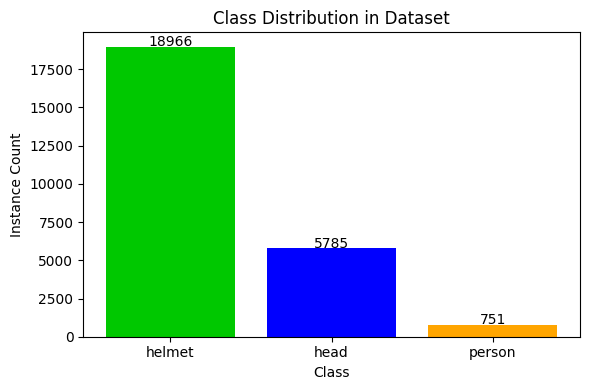

In [6]:
# Count how many bounding boxes exist for each class across the entire dataset.
# Counter is like a dictionary that automatically counts occurrences.
class_counts = Counter()
for ann in annotations:
    for obj in ann["objects"]:
        class_counts[obj["name"]] += 1    # Add 1 to the count for this class name

total_boxes = sum(class_counts.values())  # Total number of bounding boxes in the dataset
print("Class Distribution")
print("-" * 35)
for cls, count in class_counts.most_common():   # most_common() sorts from most to least frequent
    pct = 100.0 * count / total_boxes
    print(f"  {cls:<10s}  {count:>6d}  ({pct:.1f}%)")
print(f"  {'TOTAL':<10s}  {total_boxes:>6d}")

# Create a bar chart to visualize the class distribution
fig, ax = plt.subplots(figsize=(6, 4))
classes = [c for c, _ in class_counts.most_common()]   # Class names in order
counts = [class_counts[c] for c in classes]             # Corresponding counts
bar_colors = [tuple(c / 255.0 for c in COLORS.get(cls, (128, 128, 128))) for cls in classes]  # Convert 0-255 to 0.0-1.0 for matplotlib

ax.bar(classes, counts, color=bar_colors)
ax.set_xlabel("Class")
ax.set_ylabel("Instance Count")
ax.set_title("Class Distribution in Dataset")
for i, count in enumerate(counts):
    ax.text(i, count + 50, str(count), ha="center", fontsize=10)  # Label above each bar

plt.tight_layout()
fig.savefig(os.path.join(PROJECT_ROOT, "outputs", "metrics", "class_distribution.png"), dpi=150)
plt.show()

In [7]:
# Collect the width and height of every image from the annotation metadata.
# This tells us whether the images are all the same size or vary in dimensions.
widths = [a["width"] for a in annotations]
heights = [a["height"] for a in annotations]

print("Image Size Statistics")
print("-" * 35)
print(f"  Width   min={min(widths)}  max={max(widths)}  mean={np.mean(widths):.0f}")
print(f"  Height  min={min(heights)}  max={max(heights)}  mean={np.mean(heights):.0f}")

Image Size Statistics
-----------------------------------
  Width   min=415  max=416  mean=416
  Height  min=415  max=416  mean=416


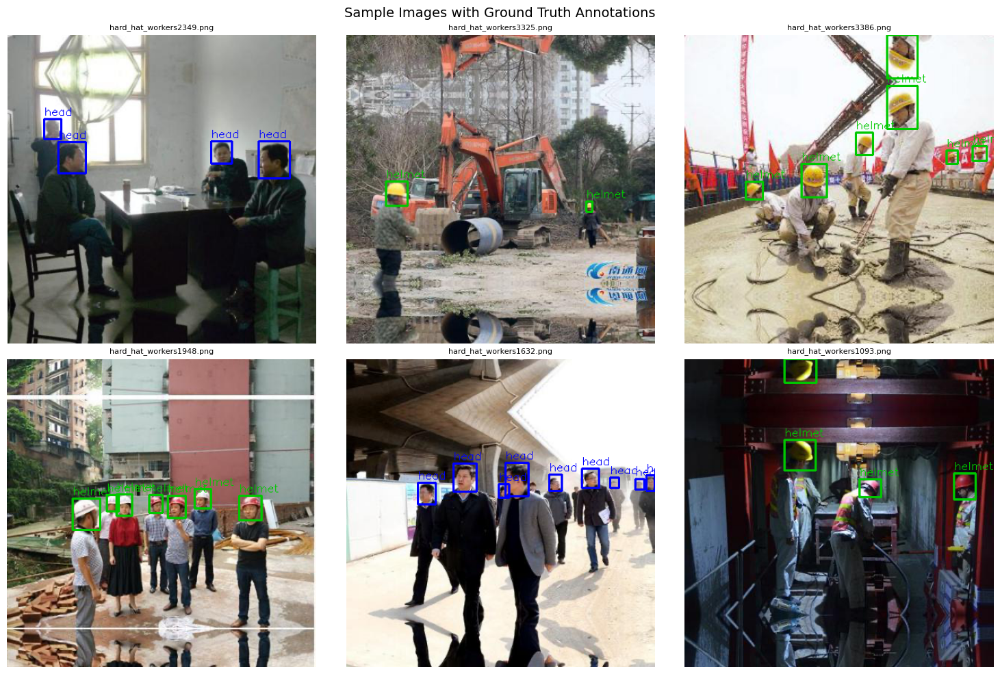

In [8]:
import warnings

# Pick 6 random images to display as samples.
# RandomState(42) ensures we get the same 6 images every time for reproducibility.
rng = np.random.RandomState(42)
sample_indices = rng.choice(len(annotations), size=6, replace=False)  # Pick 6 unique random indices

fig, axes = plt.subplots(2, 3, figsize=(15, 10))  # 2 rows, 3 columns
axes = axes.flatten()                               # Flatten 2D grid into a list for easy looping

for ax, idx in zip(axes, sample_indices):
    ann = annotations[idx]
    img = cv2.imread(os.path.join(IMAGES_DIR, ann["filename"]))  # Load image from disk

    if img is None:
        warnings.warn(f"Could not load image: {ann['filename']}. Skipping.")
        ax.set_title(f"Failed to load: {ann['filename']}", fontsize=8, color='red')
        ax.axis("off")
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)                   # OpenCV uses BGR, matplotlib needs RGB

    for obj in ann["objects"]:
        color = COLORS.get(obj["name"], (128, 128, 128))
        cv2.rectangle(img, (obj["xmin"], obj["ymin"]), (obj["xmax"], obj["ymax"]), color, 2)  # Draw bounding box
        cv2.putText(img, obj["name"], (obj["xmin"], obj["ymin"] - 5),                        # Label above box
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

    ax.imshow(img)
    ax.set_title(ann["filename"], fontsize=8)
    ax.axis("off")  # Hide axis ticks

plt.suptitle("Sample Images with Ground Truth Annotations", fontsize=14)
plt.tight_layout()
fig.savefig(os.path.join(PROJECT_ROOT, "outputs", "sample_detections", "dataset_samples.png"), dpi=150)
plt.show()

## 4. Convert Annotations (VOC XML to YOLO format)

Converts Pascal VOC bounding boxes from absolute pixel coordinates to
YOLO normalized format. Skips conversion if label files already exist.

In [9]:
YOLO_LABELS_DIR = os.path.join(RAW_DIR, "labels_yolo")  # Output directory for converted labels
os.makedirs(YOLO_LABELS_DIR, exist_ok=True)

# Check if we already converted the labels in a previous run
existing_labels = [f for f in os.listdir(YOLO_LABELS_DIR) if f.endswith(".txt")] if os.path.isdir(YOLO_LABELS_DIR) else []

if len(existing_labels) >= len(annotations):
    print(f"YOLO labels already exist ({len(existing_labels)} files), skipping conversion")
else:
    print(f"Converting {len(annotations)} annotations to YOLO format...")
    print(f"Class mapping: {CLASS_MAP}")

    total_stats = Counter()  # Track how many boxes we convert per class

    for i, ann in enumerate(annotations):
        lines = []
        for obj in ann["objects"]:
            class_name = obj["name"]
            if class_name not in CLASS_MAP:
                continue                        # Skip unknown classes
            class_id = CLASS_MAP[class_name]

            # VOC format uses absolute pixel coordinates: (xmin, ymin, xmax, ymax)
            # YOLO format uses normalized 0-1 coordinates: (x_center, y_center, width, height)
            x_center = (obj["xmin"] + obj["xmax"]) / 2.0 / ann["width"]   # Midpoint of left/right edges, normalized
            y_center = (obj["ymin"] + obj["ymax"]) / 2.0 / ann["height"]  # Midpoint of top/bottom edges, normalized
            box_w = (obj["xmax"] - obj["xmin"]) / ann["width"]            # Box width, normalized
            box_h = (obj["ymax"] - obj["ymin"]) / ann["height"]           # Box height, normalized

            lines.append(f"{class_id} {x_center:.6f} {y_center:.6f} {box_w:.6f} {box_h:.6f}")  # One line per object
            total_stats[class_name] += 1

        # Save one .txt file per image, named the same as the image but with .txt extension
        label_name = os.path.splitext(ann["filename"])[0] + ".txt"
        with open(os.path.join(YOLO_LABELS_DIR, label_name), "w") as f:
            f.write("\n".join(lines) + "\n" if lines else "")

        if (i + 1) % 1000 == 0:  # Print progress every 1000 files
            print(f"  Converted {i + 1}/{len(annotations)}")

    print(f"\nConversion complete")
    print(f"  Total boxes: {sum(total_stats.values())}")
    for cls, count in total_stats.most_common():
        print(f"    {cls:<10s}  {count:>6d}")

Converting 5000 annotations to YOLO format...
Class mapping: {'helmet': 0, 'head': 1, 'person': 2}
  Converted 1000/5000
  Converted 2000/5000
  Converted 3000/5000
  Converted 4000/5000
  Converted 5000/5000

Conversion complete
  Total boxes: 25502
    helmet       18966
    head          5785
    person         751


## 5. Train/Val/Test Split

70% train, 20% validation, 10% test with stratification by primary class.
Skips if split directories are already populated.

In [10]:
import shutil
from collections import defaultdict

SPLIT_RATIOS = {"train": 0.70, "val": 0.20, "test": 0.10}  # How much data goes into each split
RANDOM_SEED = 42  # Fixed seed so the split is identical every time we run it

train_img_dir = os.path.join(PROJECT_ROOT, "data", "images", "train")
existing_train = os.listdir(train_img_dir) if os.path.isdir(train_img_dir) else []

if len(existing_train) > 0:  # Skip if we already split the data before
    for split in ["train", "val", "test"]:
        n = len(os.listdir(os.path.join(PROJECT_ROOT, "data", "images", split)))
        print(f"  {split}: {n} images (already split)")
else:
    # Get all image filenames and strip extensions (e.g. "hard_hat_workers0.png" -> "hard_hat_workers0")
    image_files = sorted(f for f in os.listdir(IMAGES_DIR) if f.lower().endswith((".png", ".jpg", ".jpeg")))
    image_names = [os.path.splitext(f)[0] for f in image_files]  # Base names used to match images to labels

    # --- Stratified splitting ---
    # We group images by their most common class, then split each group separately.
    # This ensures train/val/test all have similar class proportions.

    rng = np.random.RandomState(RANDOM_SEED)                 # Random number generator with fixed seed
    class_groups = defaultdict(list)                          # Auto-creates an empty list for new keys

    for name in image_names:
        label_path = os.path.join(YOLO_LABELS_DIR, name + ".txt")  # Path to this image's YOLO label file
        primary = "empty"                                          # Default if the image has no labels

        if os.path.exists(label_path):
            classes_in_file = []
            with open(label_path) as f:
                for line in f:
                    if line.strip():                                # Skip empty lines
                        classes_in_file.append(line.split()[0])    # First value on each line is the class ID

            if classes_in_file:
                # Find the most common class in this image
                # Counter.most_common(1) returns [(class_id, count)], we grab just the class_id
                primary = Counter(classes_in_file).most_common(1)[0][0]

        class_groups[primary].append(name)  # Group this image under its primary class

    # Split each class group independently to maintain balanced proportions
    splits = {"train": [], "val": [], "test": []}

    for cls, names in class_groups.items():
        rng.shuffle(names)                                  # Randomly reorder images in this class group
        n = len(names)
        n_train = int(n * SPLIT_RATIOS["train"])            # 70% for training
        n_val = int(n * SPLIT_RATIOS["val"])                # 20% for validation

        splits["train"].extend(names[:n_train])             # First 70% goes to training
        splits["val"].extend(names[n_train:n_train + n_val])  # Next 20% goes to validation
        splits["test"].extend(names[n_train + n_val:])      # Remaining 10% goes to test

    # Copy image and label files into their respective split directories
    for split_name, names in splits.items():
        img_dest = os.path.join(PROJECT_ROOT, "data", "images", split_name)
        lbl_dest = os.path.join(PROJECT_ROOT, "data", "labels", split_name)
        os.makedirs(img_dest, exist_ok=True)
        os.makedirs(lbl_dest, exist_ok=True)

        for name in names:
            for ext in (".png", ".jpg", ".jpeg"):                              # Try each possible image extension
                src = os.path.join(IMAGES_DIR, name + ext)
                if os.path.exists(src):
                    shutil.copy2(src, os.path.join(img_dest, name + ext))      # Copy image to split folder
                    break

            label_src = os.path.join(YOLO_LABELS_DIR, name + ".txt")
            if os.path.exists(label_src):
                shutil.copy2(label_src, os.path.join(lbl_dest, name + ".txt"))  # Copy matching label file

        print(f"  {split_name}: {len(names)} images")

    print("Split complete.")

  train: 3499 images
  val: 999 images
  test: 502 images
Split complete.


In [11]:
# Create the data.yaml configuration file that tells YOLO where to find
# the training, validation, and test images, how many classes there are,
# and what the class names are.
#
# Using an absolute path for "path" ensures YOLO can find the data
# regardless of what directory training is started from.
data_yaml_path = os.path.join(PROJECT_ROOT, "data", "data.yaml")
data_yaml_content = f"""path: {os.path.join(PROJECT_ROOT, 'data')}
train: images/train
val: images/val
test: images/test

nc: 3
names: ['helmet', 'head', 'person']
"""

with open(data_yaml_path, "w") as f:
    f.write(data_yaml_content)

print(f"data.yaml written to {data_yaml_path}")
print(data_yaml_content)

data.yaml written to /content/drive/MyDrive/ppe-detection-v2/data/data.yaml
path: /content/drive/MyDrive/ppe-detection-v2/data
train: images/train
val: images/val
test: images/test

nc: 3
names: ['helmet', 'head', 'person']



## 5.5 Oversample Person Class

The person class has only 751 annotations (2.9% of the dataset) compared to
18,966 for helmet (74.4%).

In [12]:
# --- Person class oversampling ---
# The person class has ~574 training instances vs ~13,400 for helmet.
# Duplicating person images 5x reduces the imbalance so the model
# actually learns to detect this class.

PERSON_CLASS_ID = "2"  # Class ID for "person" in our YOLO label files
COPIES = PERSON_OVERSAMPLE             # Set in Configuration cell above

train_img_dir = os.path.join(PROJECT_ROOT, "data", "images", "train")
train_lbl_dir = os.path.join(PROJECT_ROOT, "data", "labels", "train")

# Check if oversampling was already done in a previous run
existing_dups = [f for f in os.listdir(train_lbl_dir) if "_dup" in f]

if len(existing_dups) > 0:
    print(f"Oversampling already done ({len(existing_dups)} duplicates exist)")
else:
    # Step 1 - Find all training label files that contain person annotations
    person_basenames = []
    for label_file in sorted(os.listdir(train_lbl_dir)):
        if not label_file.endswith(".txt"):
            continue
        label_path = os.path.join(train_lbl_dir, label_file)
        with open(label_path) as f:
            for line in f:
                if line.strip().startswith(PERSON_CLASS_ID + " "):  # This label has a person box
                    person_basenames.append(os.path.splitext(label_file)[0])
                    break  # Only need to find one person box per image

    print(f"Found {len(person_basenames)} training images with person annotations")

    # Step 2 - Copy each image and label file N times with new names
    created = 0
    for basename in person_basenames:
        # Find the image file (could be .png, .jpg, or .jpeg)
        img_path = None
        for ext in [".png", ".jpg", ".jpeg"]:
            candidate = os.path.join(train_img_dir, basename + ext)
            if os.path.exists(candidate):
                img_path = candidate
                img_ext = ext
                break

        if img_path is None:
            continue

        label_path = os.path.join(train_lbl_dir, basename + ".txt")

        for i in range(1, COPIES + 1):
            new_name = f"{basename}_dup{i}"
            new_img = os.path.join(train_img_dir, new_name + img_ext)
            new_lbl = os.path.join(train_lbl_dir, new_name + ".txt")

            if not os.path.exists(new_img):  # Avoid re-copying
                shutil.copy2(img_path, new_img)   # Duplicate the image
                shutil.copy2(label_path, new_lbl)  # Duplicate the matching label
                created += 1

    print(f"Created {created} new image-label pairs")
    total = len([f for f in os.listdir(train_img_dir) if not f.startswith(".")])
    print(f"Training set now has {total} images")

Found 112 training images with person annotations
Created 560 new image-label pairs
Training set now has 4059 images


## 6. Model Training

Fine-tune YOLO26s on the PPE dataset.

In [14]:
import json

# --- Training ---
RUNS_DIR = os.path.join(PROJECT_ROOT, "runs", "detect")          # Where YOLO saves training runs
RUN_NAME = f"ppe_{MODEL_NAME}_v2"                                 # Derived from MODEL_NAME
best_pt = os.path.join(RUNS_DIR, RUN_NAME, "weights", "best.pt")  # Best model checkpoint path

# Check if a last.pt checkpoint exists to determine if we should resume
last_pt = os.path.join(RUNS_DIR, RUN_NAME, "weights", "last.pt")
RESUME = os.path.exists(last_pt) # Dynamically set RESUME based on file existence

# Save training configuration as JSON for reproducibility/reporting
training_config_path = os.path.join(PROJECT_ROOT, "outputs", "metrics", "training_config.json")
training_config = {
    "run_name": RUN_NAME,
    "project": RUNS_DIR,
    "resume": RESUME, # Use the dynamically determined RESUME value
    "data": data_yaml_path,
    "model": f"{MODEL_NAME}.pt",
    "epochs": EPOCHS,
    "imgsz": 640,
    "batch": BATCH_SIZE,
    "patience": PATIENCE,
    "optimizer": "auto",
    "lr0": 0.01,
    "lrf": 0.01,
    "copy_paste": 0.5,
    "mixup": 0.15,
    "save": True,
    "save_period": 10,
    "plots": True,
    "device": str(device),
}

with open(training_config_path, "w") as f:
    json.dump(training_config, f, indent=2)
print(f"Training config saved to {training_config_path}")

if RESUME:
    print(f"Resuming training from {last_pt}")
    model = YOLO(last_pt)
    results = model.train(resume=True)
    print("Training resumed and complete.")
else:
    print("No previous checkpoint found. Starting new training.")
    # Load the pretrained model. "Pretrained" means the model already
    # knows how to detect common objects. We fine-tune it for our PPE classes.
    model = YOLO(f"{MODEL_NAME}.pt")

    results = model.train(
        data=training_config["data"],   # Path to data.yaml describing our dataset
        epochs=training_config["epochs"],
        imgsz=training_config["imgsz"],
        batch=training_config["batch"],
        patience=training_config["patience"],
        optimizer=training_config["optimizer"],
        lr0=training_config["lr0"],
        lrf=training_config["lrf"],
        copy_paste=training_config["copy_paste"],
        mixup=training_config["mixup"],
        project=training_config["project"],
        name=training_config["run_name"],
        save=training_config["save"],
        save_period=training_config["save_period"],
        plots=training_config["plots"],
        device=training_config["device"],
    )

    print("Training complete.")
    print(f"Best model saved at {best_pt}")

Training config saved to /content/drive/MyDrive/ppe-detection-v2/outputs/metrics/training_config.json
No previous checkpoint found. Starting new training.
Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.5, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ppe-detection-v2/data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, mod

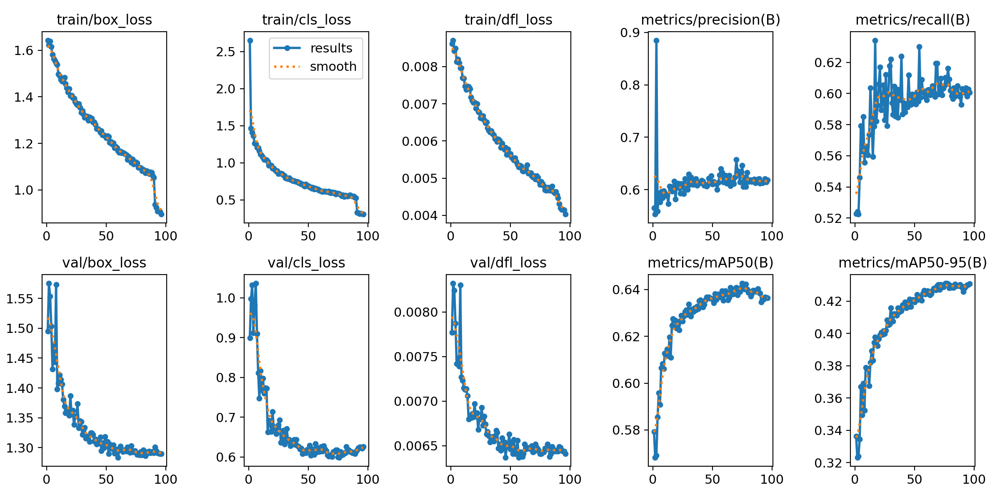

In [15]:
# After training, YOLO saves a results.png image that shows how the loss
# and metrics changed over each epoch. This is useful for checking whether
# the model was still improving or had converged.
results_png = os.path.join(RUNS_DIR, RUN_NAME, "results.png")
if os.path.exists(results_png):
    from IPython.display import Image, display
    display(Image(filename=results_png, width=900))
else:
    print("No training curves found. Run training first.")

## 7. Evaluation on Test Set

Load the best model, run validation on the test split, and display all key metrics.

In [16]:
import glob
import json
import pandas as pd

best_pt = os.path.join(RUNS_DIR, RUN_NAME, "weights", "best.pt")  # Path to best model checkpoint

# Save validation/evaluation configuration as JSON for reproducibility/reporting
val_config_path = os.path.join(PROJECT_ROOT, "outputs", "metrics", "val_config.json")
val_config = {
    "model_path": best_pt,
    "data": data_yaml_path,
    "split": "test",
    "device": str(device),
    "plots": True,
    "conf_threshold": CONF_THRESHOLD,
}
with open(val_config_path, "w") as f:
    json.dump(val_config, f, indent=2)
print(f"Validation config saved to {val_config_path}")

if not os.path.exists(best_pt):
    print(f"ERROR: No trained model found at {best_pt}")
    print("Run the training cell first.")
else:
    eval_model = YOLO(best_pt)  # Load the best model checkpoint

    # Run the model on the test set and compute detection metrics.
    # split="test" uses the test images from data.yaml, plots=True generates charts.
    metrics = eval_model.val(
        data=val_config["data"],
        split=val_config["split"],
        device=val_config["device"],
        plots=val_config["plots"],
    )

    class_names = ["helmet", "head", "person"]

    # --- Print overall metrics ---
    # mAP@50 = mean Average Precision at 50% IoU (a prediction is "correct" if it
    #          overlaps at least 50% with the ground truth box)
    # mAP@50-95 = same but averaged over 50% to 95% IoU thresholds (stricter)
    # Precision = of all detections the model made, what fraction were correct
    # Recall = of all real objects, what fraction did the model find
    print("=" * 55)
    print("  TEST SET EVALUATION RESULTS")
    print("=" * 55)
    print(f"\n  Overall mAP@50:      {metrics.box.map50:.4f}")
    print(f"  Overall mAP@50-95:  {metrics.box.map:.4f}")
    print(f"  Overall Precision:   {metrics.box.mp:.4f}")
    print(f"  Overall Recall:      {metrics.box.mr:.4f}")

    # Build a per-class metrics table
    rows = []
    for i, name in enumerate(class_names):
        if i < len(metrics.box.ap50):
            rows.append({
                "Class": name,
                "mAP@50": f"{metrics.box.ap50[i]:.4f}",
                "mAP@50-95": f"{metrics.box.maps[i]:.4f}",
                "Precision": f"{metrics.box.p[i]:.4f}",
                "Recall": f"{metrics.box.r[i]:.4f}",
            })

    df = pd.DataFrame(rows)
    print("\nPer-Class Metrics")
    print(df.to_string(index=False))

    speed = metrics.speed  # Inference speed in milliseconds per image
    print(f"\nInference Speed")
    print(f"  Preprocess:   {speed.get('preprocess', 0):.1f} ms")
    print(f"  Inference:    {speed.get('inference', 0):.1f} ms")
    print(f"  Postprocess:  {speed.get('postprocess', 0):.1f} ms")

    # Save metrics to a text file for the report
    metrics_path = os.path.join(PROJECT_ROOT, "outputs", "metrics", "test_results.txt")
    with open(metrics_path, "w") as f:
        f.write("PPE Detection Model Evaluation Results\n")
        f.write("=" * 50 + "\n\n")
        f.write(f"mAP@50:      {metrics.box.map50:.4f}\n")
        f.write(f"mAP@50-95:   {metrics.box.map:.4f}\n")
        f.write(f"Precision:   {metrics.box.mp:.4f}\n")
        f.write(f"Recall:      {metrics.box.mr:.4f}\n\n")
        f.write(df.to_string(index=False) + "\n")
    print(f"\nMetrics saved to {metrics_path}")

Validation config saved to /content/drive/MyDrive/ppe-detection-v2/outputs/metrics/val_config.json
Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,466,341 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.2 ms, read: 47.2±17.0 MB/s, size: 256.3 KB)
val: Scanning /content/drive/MyDrive/ppe-detection-v2/data/labels/test... 502 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 502/502 85.8it/s 5.8s
val: New cache created: /content/drive/MyDrive/ppe-detection-v2/data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.1it/s 15.3s
                   all        502       2502      0.625      0.604      0.643      0.433
                helmet        457       1870      0.943      0.927       0.97      0.652
                  head         91        574      0.934      0.885      0.949      0.644
                pe

### 7.1 Confusion Matrix and PR Curves


Normalized Confusion Matrix


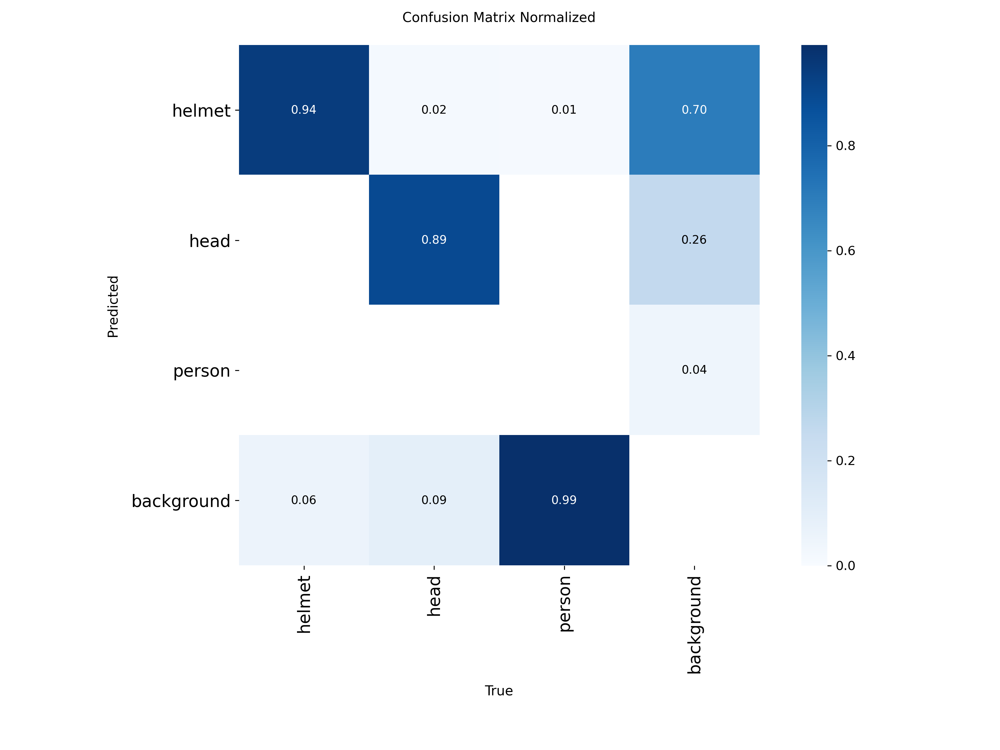


Confusion Matrix


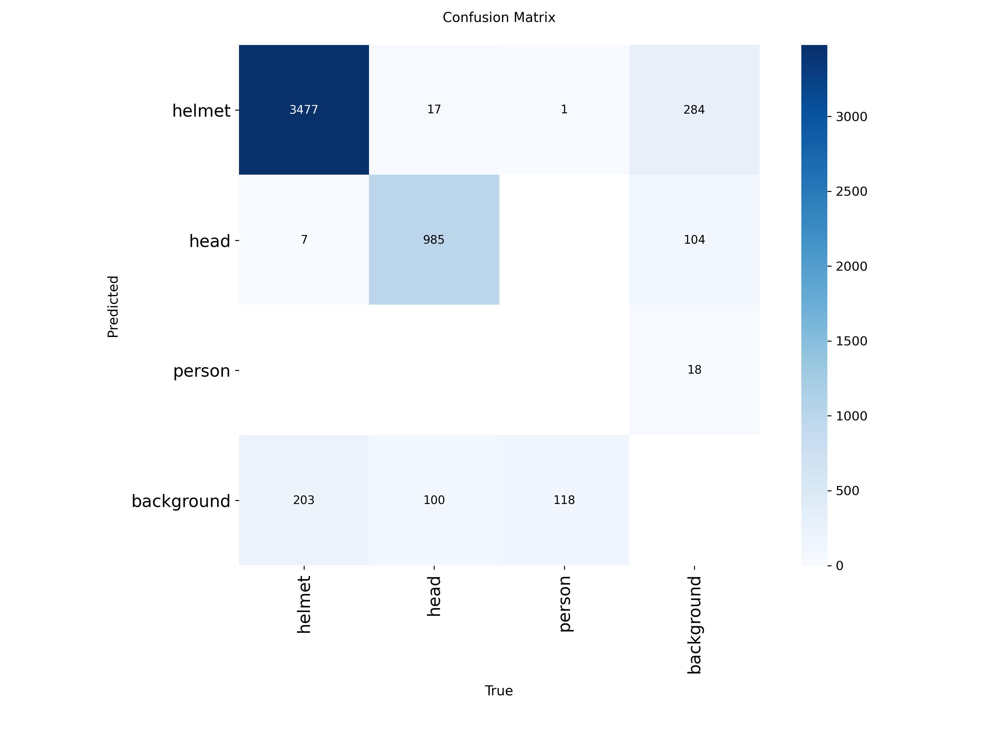

Precision-Recall Curve not found at /content/drive/MyDrive/ppe-detection-v2/runs/detect/ppe_yolo26s_v2/PR_curve.png
F1 Curve not found at /content/drive/MyDrive/ppe-detection-v2/runs/detect/ppe_yolo26s_v2/F1_curve.png


In [17]:
from IPython.display import Image, display

# YOLO automatically generates several diagnostic plots during training.
# We copy them into outputs/metrics/ and display them inline in the notebook.
plot_files = {
    "confusion_matrix_normalized.png": "Normalized Confusion Matrix",
    "confusion_matrix.png": "Confusion Matrix",
    "PR_curve.png": "Precision-Recall Curve",
    "F1_curve.png": "F1 Curve",
}

run_dir = os.path.join(RUNS_DIR, RUN_NAME)
metrics_out = os.path.join(PROJECT_ROOT, "outputs", "metrics")

for filename, title in plot_files.items():
    src = os.path.join(run_dir, filename)
    if os.path.exists(src):
        # Copy plot to the outputs folder so it is easy to find for the report
        shutil.copy2(src, os.path.join(metrics_out, filename))
        print(f"\n{title}")
        display(Image(filename=src, width=600))
    else:
        print(f"{title} not found at {src}")

### 7.2 Sample Detections on Test Images

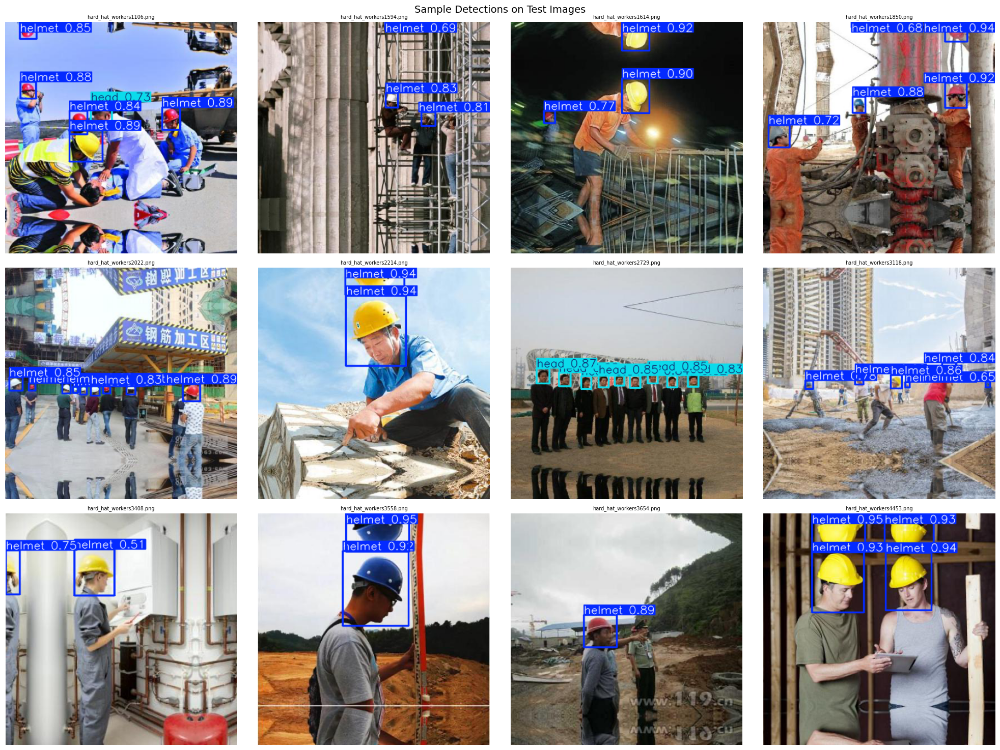

Individual detection images saved to /content/drive/MyDrive/ppe-detection-v2/outputs/sample_detections


In [18]:
test_images_dir = os.path.join(PROJECT_ROOT, "data", "images", "test")
test_images = sorted(glob.glob(os.path.join(test_images_dir, "*.*")))  # All test image file paths
sample_out = os.path.join(PROJECT_ROOT, "outputs", "sample_detections")

if not os.path.exists(best_pt):
    print("No model found. Train first.")
else:
    det_model = YOLO(best_pt)  # Load the trained model

    rng = np.random.RandomState(42)
    sample_idx = rng.choice(len(test_images), size=min(12, len(test_images)), replace=False)  # Pick 12 random test images
    selected = [test_images[i] for i in sorted(sample_idx)]

    fig, axes = plt.subplots(3, 4, figsize=(20, 15))  # 3 rows x 4 columns grid
    axes = axes.flatten()

    for ax, img_path in zip(axes, selected):
        results = det_model.predict(img_path, conf=CONF_THRESHOLD, device=str(device), verbose=False)  # Run detection, confidence set in Configuration cell above
        annotated = results[0].plot()                   # Draw boxes, labels, and scores onto the image
        annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for matplotlib
        ax.imshow(annotated)
        ax.set_title(os.path.basename(img_path), fontsize=7)
        ax.axis("off")

        out_name = "det_" + os.path.basename(img_path)
        cv2.imwrite(os.path.join(sample_out, out_name), results[0].plot())  # Save individual detection image

    for ax in axes[len(selected):]:  # Hide unused subplot slots
        ax.axis("off")

    plt.suptitle("Sample Detections on Test Images", fontsize=14)
    plt.tight_layout()
    plt.show()
    print(f"Individual detection images saved to {sample_out}")

### 7.3 Failure Case Analysis

Identifies test images where the model's prediction count differs most from ground truth,
indicating missed detections or false positives.

Failure Case Analysis
  failure_1_hard_hat_workers4075.png  GT=14  Pred=5  missed detections
  failure_2_hard_hat_workers2544.png  GT=8  Pred=1  missed detections
  failure_3_hard_hat_workers3685.png  GT=11  Pred=5  missed detections
  failure_4_hard_hat_workers3821.png  GT=10  Pred=16  false positives
  failure_5_hard_hat_workers1559.png  GT=11  Pred=6  missed detections
  failure_6_hard_hat_workers1697.png  GT=11  Pred=6  missed detections
  failure_7_hard_hat_workers2171.png  GT=1  Pred=6  false positives
  failure_8_hard_hat_workers4750.png  GT=9  Pred=4  missed detections


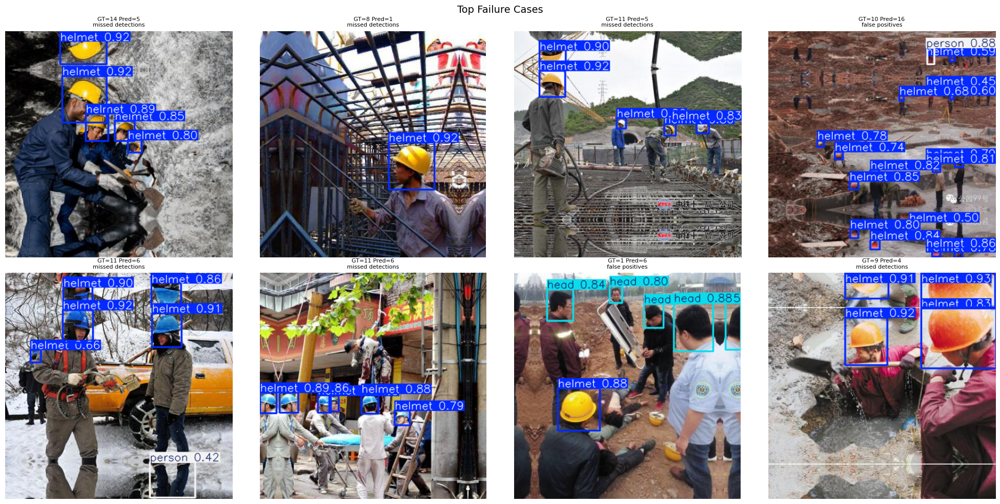


Failure images saved to /content/drive/MyDrive/ppe-detection-v2/outputs/sample_detections/failures


In [19]:
labels_test_dir = os.path.join(PROJECT_ROOT, "data", "labels", "test")  # Ground truth labels for test images
failure_dir = os.path.join(sample_out, "failures")
os.makedirs(failure_dir, exist_ok=True)

if not os.path.exists(best_pt):
    print("No model found. Train first.")
else:
    fail_model = YOLO(best_pt)

    # For each test image, compare how many objects the model predicted vs
    # how many actually exist in the ground truth labels
    failures = []
    for img_path in test_images:
        basename = os.path.splitext(os.path.basename(img_path))[0]     # Strip path and extension
        label_path = os.path.join(labels_test_dir, basename + ".txt")

        gt_count = 0  # Ground truth object count
        if os.path.exists(label_path):
            with open(label_path) as f:
                gt_count = sum(1 for line in f if line.strip())        # Count non-empty lines

        results = fail_model.predict(img_path, conf=CONF_THRESHOLD, device=str(device), verbose=False)
        pred_count = len(results[0].boxes)                             # Number of predicted detections
        diff = abs(gt_count - pred_count)                              # How far off the model was

        if diff > 0:  # Only keep images where the model made mistakes
            failures.append({
                "path": img_path,
                "gt": gt_count,
                "pred": pred_count,
                "diff": diff,
                "result": results[0],
            })

    failures.sort(key=lambda x: x["diff"], reverse=True)  # Worst failures first
    top_failures = failures[:8]                             # Keep the 8 worst cases

    if not top_failures:
        print("No obvious failure cases found.")
    else:
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        axes = axes.flatten()

        print("Failure Case Analysis")
        print("=" * 60)

        for i, (ax, fail) in enumerate(zip(axes, top_failures)):
            annotated = fail["result"].plot()
            annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
            ax.imshow(annotated_rgb)

            reason = "missed detections" if fail["pred"] < fail["gt"] else "false positives"
            ax.set_title(f"GT={fail['gt']} Pred={fail['pred']}\n{reason}", fontsize=8)
            ax.axis("off")

            out_name = f"failure_{i+1}_{os.path.basename(fail['path'])}"
            cv2.imwrite(os.path.join(failure_dir, out_name), annotated)  # Save each failure image
            print(f"  {out_name}  GT={fail['gt']}  Pred={fail['pred']}  {reason}")

        for ax in axes[len(top_failures):]:
            ax.axis("off")

        plt.suptitle("Top Failure Cases", fontsize=14)
        plt.tight_layout()
        plt.show()
        print(f"\nFailure images saved to {failure_dir}")

## 8. Video Inference

Downloads clips from YouTube URLs between specified start and end times,
then runs the trained model on each clip and saves the annotated output.
Supports multiple videos and multiple time slices per video.

In [20]:
VIDEO_DIR = os.path.join(PROJECT_ROOT, "data", "test_videos")
os.makedirs(VIDEO_DIR, exist_ok=True)

# Install yt-dlp and ffmpeg if needed
if IS_COLAB:
    !pip install -q yt-dlp
    !apt-get install -y -qq ffmpeg > /dev/null 2>&1
else:
    import shutil as _shutil
    if not _shutil.which("yt-dlp"):
        print("WARNING: yt-dlp not found. Install it with: pip install yt-dlp")
    if not _shutil.which("ffmpeg"):
        print("WARNING: ffmpeg not found. Install it with: sudo apt-get install ffmpeg")

import subprocess

def download_clip(url, start, end, output_path):
    """Download a single time-range clip and strip its audio."""
    cmd = [
        "yt-dlp",
        "--download-sections", f"*{start}-{end}",  # Time range to extract
        "--force-keyframes-at-cuts",                 # Clean cuts at exact timestamps
        "-f", "best[height<=720]",                   # Best quality up to 720p
        "-o", output_path,                           # Output file path
        url,
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(f"  Download failed: {result.stderr.strip()}")
        return False

    # Strip audio track if present
    probe = subprocess.run(
        ["ffprobe", "-v", "error", "-select_streams", "a",
         "-show_entries", "stream=codec_type", output_path],
        capture_output=True, text=True,
    )
    if "audio" in probe.stdout:
        tmp = output_path + ".tmp.mp4"
        subprocess.run(["ffmpeg", "-y", "-i", output_path, "-an", "-c:v", "copy", tmp],
                       capture_output=True)
        os.replace(tmp, output_path)
    return True

# Download all clips
downloaded = 0
for vid_idx, (url, slices) in enumerate(VIDEOS):
    print(f"\nVideo {vid_idx + 1}: {url}")
    for slice_idx, (start, end) in enumerate(slices):
        filename = f"clip_v{vid_idx + 1}_s{slice_idx + 1}.mp4"
        output_path = os.path.join(VIDEO_DIR, filename)

        if os.path.exists(output_path):
            size_kb = os.path.getsize(output_path) / 1024
            print(f"  {filename} already exists ({size_kb:.0f} KB), skipping")
            continue

        print(f"  Downloading {start} to {end}...")
        if download_clip(url, start, end, output_path):
            size_kb = os.path.getsize(output_path) / 1024
            print(f"  Saved {filename} ({size_kb:.0f} KB)")
            downloaded += 1

print(f"\nDone. {downloaded} new clips downloaded to {VIDEO_DIR}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 182.3/182.3 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 78.0 MB/s eta 0:00:00

Video 1: https://www.youtube.com/watch?v=s2Rb5FWxu7Q
  Saved clip_v1_s1.mp4 (725 KB)
  Saved clip_v1_s2.mp4 (651 KB)

Video 2: https://www.youtube.com/watch?v=UZ_RrLxMrEg
  Saved clip_v2_s1.mp4 (1200 KB)
  Saved clip_v2_s2.mp4 (1324 KB)

Video 3: https://www.youtube.com/watch?v=X9Lkw0Mxv1g
  Saved clip_v3_s1.mp4 (2181 KB)
  Saved clip_v3_s2.mp4 (1113 KB)

Video 4: https://www.youtube.com/watch?v=nv22uPAHgCw
  Saved clip_v4_s1.mp4 (1309 KB)

Video 5: https://www.youtube.com/watch?v=bwJ-TNu0hGM
  Saved clip_v5_s1.mp4 (1466 KB)

Done. 8 new clips downloaded to /content/drive/MyDrive/ppe-detection-v2/data/test_videos


In [21]:
# Run the trained model on all downloaded video clips
import glob

video_clips = sorted(glob.glob(os.path.join(VIDEO_DIR, "clip_*.mp4")))

if not video_clips:
    print("No video clips found. Run the download cell above first.")
elif not os.path.exists(best_pt):
    print("No trained model found. Run training first.")
else:
    vid_model = YOLO(best_pt)
    vid_out = os.path.join(PROJECT_ROOT, "outputs", "annotated_videos")

    for clip_path in video_clips:
        clip_name = os.path.splitext(os.path.basename(clip_path))[0]  # e.g. "clip_v1_s1"
        print(f"\nRunning inference on {clip_name}...")

        vid_model.predict(
            source=clip_path,             # Input video to process
            save=True,                     # Save the annotated output video
            conf=CONF_THRESHOLD,           # Minimum confidence for a detection to be shown
            show=False,                    # Do not try to open a display window
            project=vid_out,               # Output folder
            name=clip_name,                # Subfolder named after the clip
            device=str(device),            # GPU or CPU
        )
        print(f"  Saved to {vid_out}/{clip_name}/")

    print(f"\nAll {len(video_clips)} clips processed.")


Running inference on clip_v1_s1...

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/300) /content/drive/MyDrive/ppe-detection-v2/data/test_videos/clip_v1_s1.mp4: 384x640 3 helmets, 1 head, 78.6ms
video 1/1 (frame 2/300) /content/drive/MyDrive/ppe-detection-v2/data/test_videos/clip_v1_s1.mp4: 384x640 5 helmets, 11.8ms
video 1/1 (frame 3/300) /content/drive/MyDrive/ppe-detection-v2/data/test_videos/clip_v1_s1.mp4: 384x640 3 helmets, 11.7ms
video 1/1 (frame 4/300) /content/drive/MyDriv

## 9. Summary

All outputs are saved to the `outputs/` directory and the training run directory.

| Output | Location |
|--------|----------|
| Class distribution chart | `outputs/metrics/class_distribution.png` |
| Dataset sample images | `outputs/sample_detections/dataset_samples.png` |
| Training curves | `runs/detect/<RUN_NAME>/results.png` |
| Best model weights | `runs/detect/<RUN_NAME>/weights/best.pt` |
| Test metrics | `outputs/metrics/test_results.txt` |
| Confusion matrix | `outputs/metrics/confusion_matrix.png` |
| PR curve | `outputs/metrics/PR_curve.png` |
| F1 curve | `outputs/metrics/F1_curve.png` |
| Sample detections | `outputs/sample_detections/det_*.png` |
| Failure analysis | `outputs/sample_detections/failures/` |
| Annotated video | `outputs/annotated_videos/` |

### Download `outputs` folder

In [22]:
import shutil
import os
from google.colab import files

# Define the paths to the folders to be zipped
OUTPUTS_DIR = os.path.join(PROJECT_ROOT, "outputs")
RUNS_DIR_PATH = os.path.join(PROJECT_ROOT, "runs")

# Define the names for the output zip files
outputs_zip_name = "outputs.zip"
runs_zip_name = "runs.zip"

print(f"Zipping '{OUTPUTS_DIR}' into '{outputs_zip_name}'...")
shutil.make_archive(os.path.join(PROJECT_ROOT, 'outputs'), 'zip', OUTPUTS_DIR)
print(f"Zipping '{RUNS_DIR_PATH}' into '{runs_zip_name}'...")
shutil.make_archive(os.path.join(PROJECT_ROOT, 'runs'), 'zip', RUNS_DIR_PATH)

print("Download links will be generated below.")


Zipping '/content/drive/MyDrive/ppe-detection-v2/outputs' into 'outputs.zip'...
Zipping '/content/drive/MyDrive/ppe-detection-v2/runs' into 'runs.zip'...
Download links will be generated below.


Click the links below to download the zipped folders:

In [23]:
from google.colab import files
import os

outputs_zip_path = os.path.join(PROJECT_ROOT, "outputs.zip")
runs_zip_path = os.path.join(PROJECT_ROOT, "runs.zip")

if os.path.exists(outputs_zip_path):
  files.download(outputs_zip_path)
else:
  print(f"Error: {outputs_zip_path} not found.")

if os.path.exists(runs_zip_path):
  files.download(runs_zip_path)
else:
  print(f"Error: {runs_zip_path} not found.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>